#**DATA ANALYSIS REPORT**
_Student: Damiano Catasta_


_Professor: Allegra Via_
_Dataset owner: Carlo Travaglini Allocatelli_

_Dataset used: destabilisation_wt_vs_mutant.csv (Travaglini dataset)_

---
##**STEPS**:

##1. Understand the data and the scientific question;
##2. Look at the data;
##3. Clean the data;
##4. Load the data into a pandas DataFrame;
##5. Explore the data;
##6. Graphing the data;
##7. Describing the data with numbers;
##8. Check for data normality;
##9. Do some inferential statistics.

---














#**STEP 1: Understand the data and the scientific question**

##Dataset description
<p>The protein destabilisation dataset (or Travaglini dataset) was made by Prof. Carlo Travaglini Allocatelli and it's a dataset used for studying protein denaturation of a species (wt) and their mutant (mut).</p>



<br>The main task consists in determine if the mutation that occurs in the protein mut has some impact in its denaturation curve by comparing it with the wild-type protein.</p>


#**STEP 2: Look at the data**

<p>The data set consists in 48 total samples, 23 corresponding to the wild-type species, and 25 corresponding to the mutant species. Signals from the proteins were measured, each urea concentration (in M or mol/L) is linked to the fluorescence intensisty (arbitrary units or A.U.) of the sample and it's all organized in tables.

<br> The first column contains the urea concentration used for that sample, the second column contains the fluorescence signal of the wild-type and the last column contains the fluorescence signal of the mutant.

Using the data that are present in this dataset we can see if the mutation that occurred in the mutant species had relevant changes to the denaturation curve of the protein.
</p>

#**STEP 3: Clean the data**
The dataset is already in a .csv file.
We remove the last two measurements at 6.9 M and 7.2 M because it was not measured for both wt and mut.
We'll also have to remove all the null-values from the dataset.

#**STEP 4: Load the data into the pandas DataFrame**

In [ ]:
#Importing GDrive folder to colab
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Seeing the paths we are working with
!ls drive/MyDrive/data_handling_project/

 destabilisation_wt_vs_mutant.csv     'Protein denaturation.pdf'
 destabilisation_wt_vs_mutant.gsheet   travaglini_dataset_TASK.docx


In [ ]:
#Assigning the dataframe path to a variable
travaglini_path = "drive/MyDrive/data_handling_project/destabilisation_wt_vs_mutant.csv"
import pandas as pd
#Reading the .csv
df = pd.read_csv(travaglini_path)
#Removing the last 2 rows because the measurements were not done on both wt and mut
df = df.dropna()
#Setting the columns
df.columns = ['urea', 'wt', 'mut']
#View of the dataframe
df

,urea,wt,mut
0,0.0,779000.0,882170
1,0.3,795000.0,907000
2,0.6,815000.0,948040
3,0.9,833000.0,988460
4,1.2,863000.0,1070000
5,1.5,905000.0,1160000
6,1.8,938000.0,1280000
7,2.1,986000.0,1360000
8,2.4,1080000.0,1410000
9,2.7,1170000.0,1460000


#**STEP 5: Explore the data**

In [ ]:
#How big is our dataframe
df.shape

(23, 3)

In [ ]:
#Seeing the type of data we are working with
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 23 entries, 0 to 22
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   urea    23 non-null     float64
 1   wt      23 non-null     float64
 2   mut     23 non-null     int64  
dtypes: float64(2), int64(1)
memory usage: 736.0 bytes


In [ ]:
#We count the number of unique samples
samples_count = df['urea'].unique()
samples_count.size

23

There are a total of 23 samples equals to 23 different concenration of urea, our denaturant agent.

In [ ]:
#Saving the datas of every column in a different array
df_wt = df['wt']
#We clean the data by converting an unecessary float type array to int type
df_wt = df_wt.astype('i')
df_mut = df['mut']

#**STEP 6: Graphing the data**

In [ ]:
#Importing numpy and matplotlib libraries
import numpy as np
import matplotlib.pyplot as plt

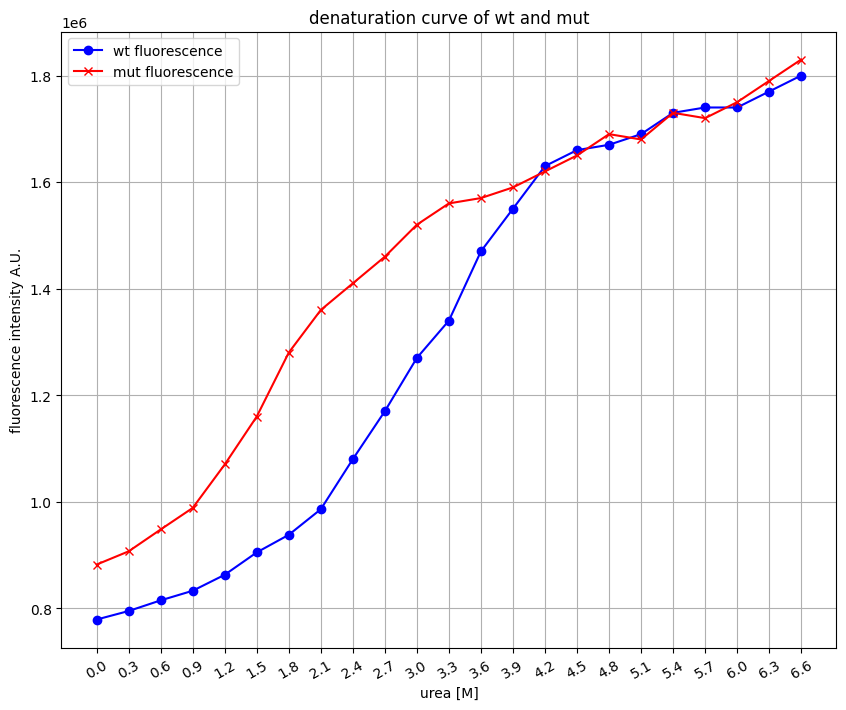

In [ ]:
#Plotting the measurements of wt and mut as function of urea concentration
plt.figure(figsize=(10,8))
plt.plot(samples_count, df_wt, 'bo-', label="wt fluorescence")
plt.plot(samples_count, df_mut, '-rx', label="mut fluorescence")
plt.xticks(samples_count, rotation=30)
plt.xlabel("urea [M]")
plt.ylabel("fluorescence intensity A.U.")
plt.title("denaturation curve of wt and mut")
plt.grid(True)
plt.legend()
plt.show()

#**STEP 7: Describing the data with numbers**

##Delta and slope calculation





In [ ]:
#We now calculate the slope of the curves above
#First calculate the delta of the urea (obviously it's 0.3 as we can instantly see on the dataset)
delta_urea = np.diff(samples_count)
delta_urea

array([0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3,
       0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3])

In [ ]:
#Now we calculate the delta for wt and mut
delta_wt = np.diff(df_wt)
delta_mut = np.diff(df_mut)
delta_wt

array([ 16000,  20000,  18000,  30000,  42000,  33000,  48000,  94000,
        90000, 100000,  70000, 130000,  80000,  80000,  30000,  10000,
        20000,  40000,  10000,      0,  30000,  30000], dtype=int32)

In [ ]:
#Now we can calculate the slopes of wt
slope_wt = delta_wt / 0.3
slope_wt

array([ 53333.33333333,  66666.66666667,  60000.        , 100000.        ,
       140000.        , 110000.        , 160000.        , 313333.33333333,
       300000.        , 333333.33333333, 233333.33333333, 433333.33333333,
       266666.66666667, 266666.66666667, 100000.        ,  33333.33333333,
        66666.66666667, 133333.33333333,  33333.33333333,      0.        ,
       100000.        , 100000.        ])

In [ ]:
#We get a mean of the slopes of wt
mean_slope_wt = np.mean(slope_wt)
mean_slope_wt

np.float64(154696.9696969697)

In [ ]:
#We do the same for mut
slope_mut = delta_mut / delta_urea
mean_slope_mut = np.mean(slope_mut)
mean_slope_mut

np.float64(143610.60606060608)

From the calculation above we can say that wt has a faster denaturation because the mean slope is higher than mut, **143611 (mut) vs 154697 (wt)**.
But form the graph we can see that mut reaches first the 50% denaturation.
Why is that? Let's see at what point we reach 50% denaturation in both wt and mut.We use the equation that are shown in _Protein denaturation.pdf_:

\

$
\displaystyle F_F= \frac{Y-Y_u}{Y_f-Y_u}
$

\

$ F_F = $ Folded fraction

$Y_f$ = Signal (fluorescence intensity) of folded protein

$Y_u$ = Signal (fluorescence intensity) of unfolded protein

$Y_n$ = Signal (fluorescence intensity) of nth sample

\

We know that the folded fraction is 0.5 so we isolate Y that is the signal when the folded fraction or the denaturation of the protein is 0.5 or 50%:

\

$
\displaystyle Y_{50}= F_{F_{0.5}} \cdot (Y_F - Y_U) + Y_U
$

\

With that we get the fluorescence intensity when the folded fraction is exactly at 0.5 or 50%.


##50% denaturation mark (0.5 folded fraction)

In [ ]:
#We calculate the fluorescence intensity of wt at 50% denaturation by using the written formula above
denaturation_50_wt = (0.5 * (df_wt.iloc[0]-df_wt.iloc[-1]) + df_wt.iloc[-1])
denaturation_50_wt

np.float64(1289500.0)

In [ ]:
#We calculate the same with mut datas
denaturation_50_mut = (0.5 * (df_mut.iloc[0]-df_mut.iloc[-1]) + df_mut.iloc[-1])
denaturation_50_mut

np.float64(1356085.0)

If we want to know at which concentration of urea corresponds the 50% denaturation of wt and mut, we must search in the dataset the corresponding urea concentration to the fluorescence intensity in the dataset.

In [ ]:
#We go through all the values of wt until we reach the one similar to denaturation_50_wt and then we search the correpsonding index in the urea array (samples_count)
for i, val in enumerate(df_wt):
  if val > denaturation_50_wt:
    urea_50_wt = samples_count[i]
    lastval = samples_count[i-1]
    print(f"The 50% denaturation of wt is between {lastval} and {urea_50_wt}")
    break

The 50% denaturation of wt is between 3.0 and 3.3


In [ ]:
#We do the exact same thing but with mut
for i, val in enumerate(df_mut):
  if val > denaturation_50_mut:
    urea_50_mut = samples_count[i]
    lastval = samples_count[i-1]
    print(f"The 50% denaturation of mut is between {lastval} and {urea_50_mut}")
    break

The 50% denaturation of mut is between 1.8 and 2.1


##Graph of denaturation curve with 50% denaturation mark

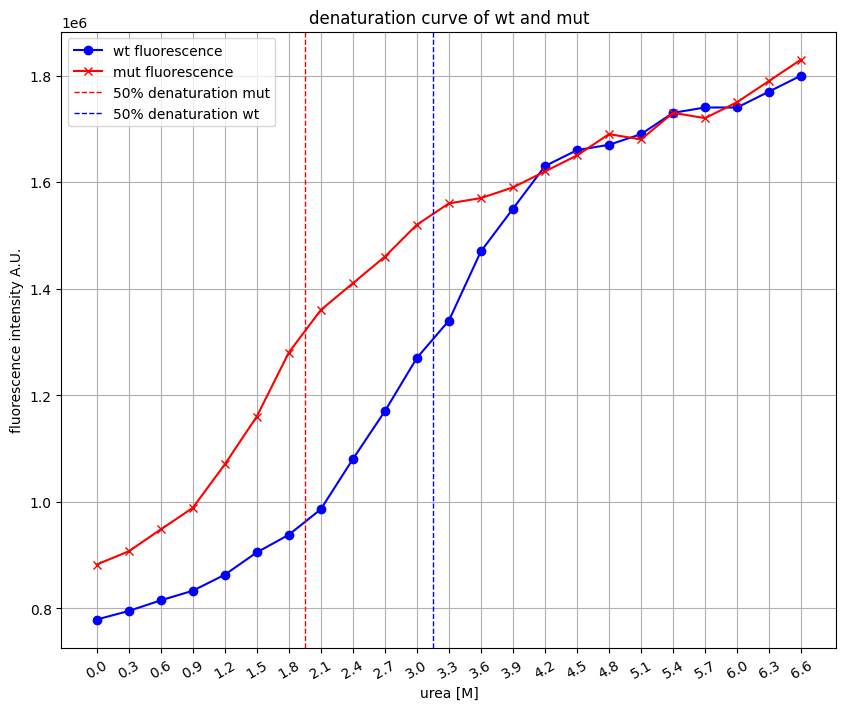

In [ ]:
#We can represent the 50% denaturation mark on the previous graph for comparison
plt.figure(figsize=(10,8))
plt.plot(samples_count, df_wt, 'bo-', label="wt fluorescence")
plt.plot(samples_count, df_mut, '-rx', label="mut fluorescence")
#Creating lines in the middle of the urea ranges of the 50% denaturation we got before
plt.axvline(1.95, color='red', linestyle='--', linewidth=1, label='50% denaturation mut')
plt.axvline(3.15, color='blue', linestyle='--', linewidth=1, label='50% denaturation wt')
plt.xticks(samples_count, rotation=30)
plt.xlabel("urea [M]")
plt.ylabel("fluorescence intensity A.U.")
plt.title("denaturation curve of wt and mut")
plt.grid(True)
plt.legend()
plt.show()

This tells us that even if the **mean** slope of wt is higher than mut, the first phase from 0% to 50% denaturation is slower than mut. We can confirm this by simply looking at the graph of the deltas of wt and mut.

##Graph of delta variations

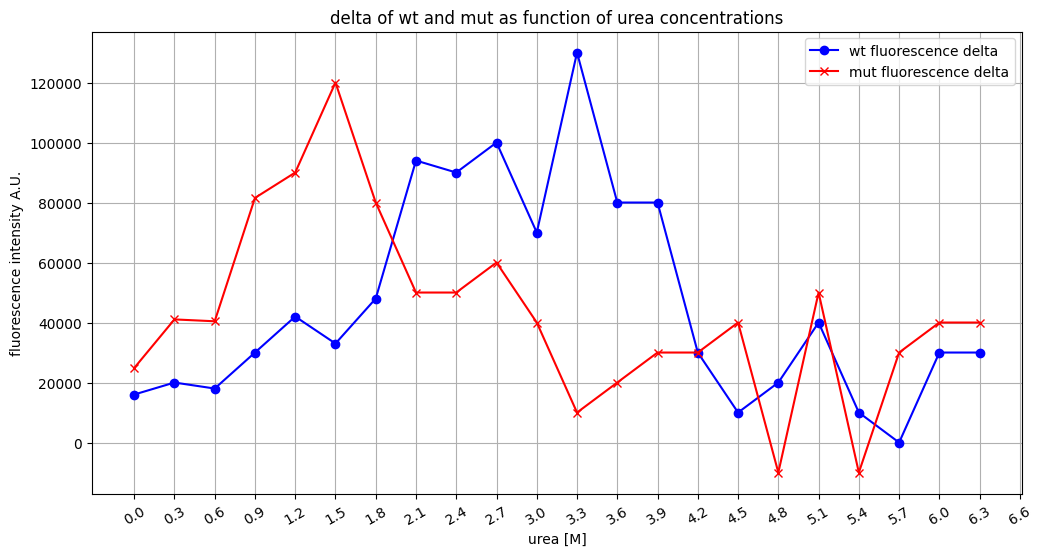

In [ ]:
#Plotting the values of the deltas of wt and mut as function of urea concentration
plt.figure(figsize=(12,6))
plt.plot(samples_count[:-1], delta_wt, 'bo-', label="wt fluorescence delta")
plt.plot(samples_count[:-1], delta_mut, '-rx', label="mut fluorescence delta")
plt.xticks(samples_count, rotation=30)
plt.xlabel("urea [M]")
plt.ylabel("fluorescence intensity A.U.")
plt.title("delta of wt and mut as function of urea concentrations")
plt.grid(True)
plt.legend()
plt.show()

From this graph we can assume that the denaturation curve can be approximated to a logistic or sigmoid curve, because what is shown in the graph above (delta as function of urea) is nothing less that the derivative of the denaturation curve.

\

It's well known that the derivative of a logistic curve is a bell-shaped curve, that we can observe in the grpah above.

\

Also the slopes of wt and mut are very similar and this suggests us that the tertiary structure was conserved in the mutation, the thing that changes most evidently is the fact that mut reaches first the peak, that corresponds to the inflection point, and this tells us that it is more susceptible to our denaturant, urea.

#**STEP 8: DATA NORMALITY**

##From fluorescence intensity to $\Delta G$

For a better vision and simplier working with this we will try to "transform" a raw value, the fluorescence intensity, into a thermodinamycal value that can be used for further analysis and studies by other people.

We can do this by calculating the K values at each step of the denaturation curve and then using this for further calculating the deltaG.

\

$
\displaystyle K = \frac{[D]}{[N]}
$

\

D = Denaturated fraction

N = Native fraction

\
$
\displaystyle K_n = \frac{Y_f - Y_n}{Y_n - Y_u}
$

\
$Y_f$ = Signal (fluorescence intensity) of folded protein

$Y_u$ = Signal (fluorescence intensity) of unfolded protein

$Y_n$ = Signal (fluorescence intensity) of nth sample


\


$
\displaystyle \Delta G_n = -RT\cdot \ln K_n
$

\

R = Gas constant (0.008314 kJ/mol)

T = Temperature (here we use 298,5 K or 25° C)

In [ ]:
#We calculate the K of wt for all the urea concentrations
k_wt = [] #New array for storing the K values
for i in df_wt:
  if i == df_wt.iloc[-1] or i == df_wt.iloc[0]: #Here we must start from 0.3 M and finish at 6.3 M or else we will get 0 and +inf
    continue
  else:
    k_wt.append((df_wt.iloc[0]-i)/(i - df_wt.iloc[-1])) #Adding the K values to the array

k_wt = np.array(k_wt) #Converting the K array to a numpy array to work with the libraries functions
k_wt

array([1.59203980e-02, 3.65482234e-02, 5.58428128e-02, 8.96478122e-02,
       1.40782123e-01, 1.84454756e-01, 2.54299754e-01, 4.18055556e-01,
       6.20634921e-01, 9.26415094e-01, 1.21956522e+00, 2.09393939e+00,
       3.08400000e+00, 5.00588235e+00, 6.29285714e+00, 6.85384615e+00,
       8.28181818e+00, 1.35857143e+01, 1.60166667e+01, 1.60166667e+01,
       3.30333333e+01])

In [ ]:
#We repeat the same steps with mut K values
k_mut = []
for i in df_mut:
  if i == df_mut.iloc[-1] or i == df_mut.iloc[0]:
    continue
  else:
    k_mut.append((df_mut.iloc[0]-i)/(i - df_mut.iloc[-1]))

k_mut = np.array(k_mut)
k_mut

array([ 0.02690141,  0.07468593,  0.12630416,  0.24714474,  0.41467164,
        0.72332727,  1.01665957,  1.2567381 ,  1.5617027 ,  2.05751613,
        2.51048148,  2.6455    ,  2.94929167,  3.51347619,  4.26572222,
        5.77021429,  5.31886667,  8.4783    ,  7.61663636, 10.847875  ,
       22.69575   ])

In [ ]:
dg_wt = -0.008314 * 298.15 * np.log(k_wt) #Calculating the deltaG
dg_wt = dg_wt[~np.isnan(dg_wt)] #Ereasing all the null-type values from the array
dg_wt

array([10.26269306,  8.20271656,  7.15192468,  5.97858071,  4.85982849,
        4.19007451,  3.39410216,  2.16187964,  1.1824271 ,  0.18946328,
       -0.49203175, -1.83196424, -2.79171413, -3.99241998, -4.55957754,
       -4.77125573, -5.24037858, -6.46728568, -6.87532664, -6.87532664,
       -8.66971232])

In [ ]:
#Same steps for mut
dg_mut = -0.008314 * 298.15 * np.log(k_mut)
dg_mut = dg_mut[~np.isnan(dg_mut)]
dg_mut

array([ 8.96236042,  6.43120593,  5.12883125,  3.46484657,  2.18202587,
        0.80287339, -0.04095586, -0.56645863, -1.1049998 , -1.78846672,
       -2.28168992, -2.41154416, -2.68100405, -3.11489874, -3.5958035 ,
       -4.34464909, -4.14275182, -5.29850051, -5.03283281, -5.90942841,
       -7.73931367])

##$\Delta G$ graph

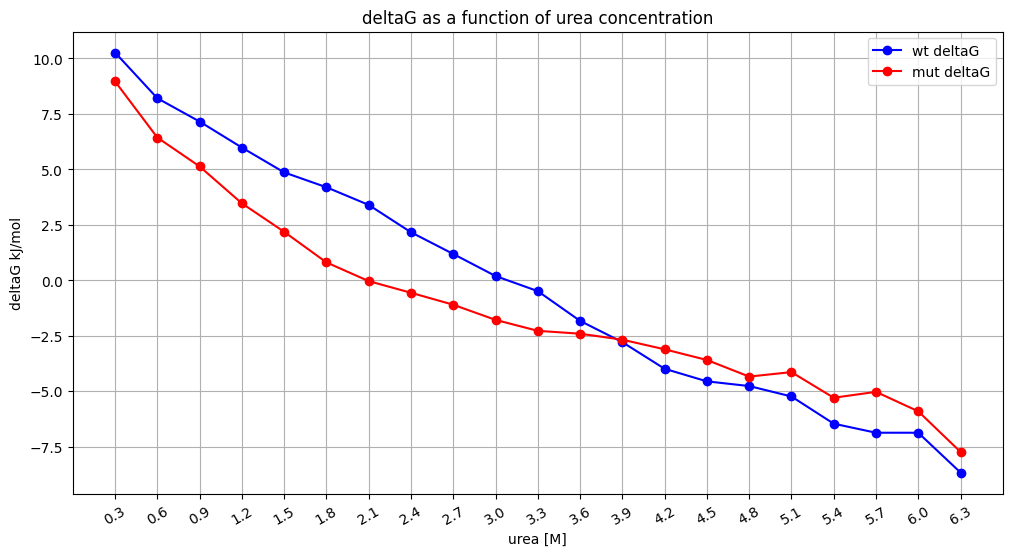

In [ ]:
urea_k = samples_count[1:-1] #We must remove the first and last urea values because we ereased the K values of the first and last measurements before

#Plotting the deltaG values for each urea concentration
plt.figure(figsize=(12,6))
plt.plot(urea_k, dg_wt, 'bo-', label="wt deltaG")
plt.plot(urea_k, dg_mut, 'ro-', label="mut deltaG")
plt.xticks(urea_k, rotation=30)
plt.xlabel("urea [M]")
plt.ylabel("deltaG kJ/mol")
plt.title("deltaG as a function of urea concentration")
plt.grid(True)
plt.legend()
plt.show()

Here we could measure at which urea concentration the deltaG is aproximately 0, so when neither the unfolded or the folded state is preferred, or our 50% denaturation mark.

The deltaG as a function of the urea concentration is strongly better for extrapolation of physical data about the denaturation of the protein. We could make a calibration line or measure the slope that is very useful if we want to know how much does 1 M of urea shifts the state of my protein from folded to unfolded.

##$\Delta\Delta G$ and slope calculation

In [ ]:
#As we did before with wt and mut slopes, we will do the same with the deltaG values
dg_wt_delta = np.diff(dg_wt) #Calculating delta of wt deltaG values
dg_mut_delta = np.diff(dg_mut) #Calculating delta of mut deltaG values

In [ ]:
dg_wt_slope = dg_wt_delta / 0.3 #To get the wt slopes we can divide by 0.3, the constant delta of urea concentrations
dg_wt_mean = np.mean(dg_wt_slope) #We get a mean of all the slopes of wt
dg_wt_mean

np.float64(-3.1554008960507387)

In [ ]:
#Same steps for mut
dg_mut_slope = dg_mut_delta / 0.3
dg_mut_mean = np.mean(dg_mut_slope)
dg_mut_mean

np.float64(-2.783612348793468)

In [ ]:
#We now repeat the same process but only for the values that are >= 0
dg_wt_slope_50 = dg_wt_delta[0:10] / 0.3 #The first 11 values of wt are >= 0
dg_wt_mean_50 = np.mean(dg_wt_slope_50) #Mean of the slopes
dg_wt_mean_50

np.float64(-3.5849082684719966)

In [ ]:
dg_mut_slope_50 = dg_mut_delta[0:6] / 0.3 #The first 7 values of mut are >=0
dg_mut_mean_50 = np.mean(dg_mut_slope_50)
dg_mut_mean_50

np.float64(-5.001842376421674)

As we said earlier, the overall mean of wt slope is higher than the one of mut, but if we measure the slope of only the half before reaching the 50% denaturation mark (3.3 M for wt and 2.1 M for mut) the mean slope is higher in wt (remeber that in this case we are talking about decreasing values of deltaG, so higher slope means the protein is more stable to rising urea concentrations beacuse it decreases slower compared to mut).

#**STEP 9: INFERENTIAL STATISTICS**

##Standard deviation

In [ ]:
#Calculate the standard deviation of deltaG slope of wt
std_wt = np.std(dg_wt_slope)
std_wt

np.float64(1.61604262830255)

In [ ]:
#Calculate the standard deviation of deltaG slope of mut
std_mut = np.std(dg_mut_slope)
std_mut

np.float64(2.247783780719832)

The standard deviation helps us to understand if the deltaG values are "linear", this will be the case of a low standard deviation. In this case we could say the the standard deviation is either not high or low, it's somewhat between and on the graph we could reasonably drawn a line that matches most of the points of the curve.

##SEM and uncertainty

As last step we can proceed to calculate the Standard error of the mean (SEM) if we want our datas and calculation to be useful, because we are examinating datas of a single experiment and on a larger scale we must introduce the SEM in that statistics.

$
\displaystyle SEM = \frac{\sigma}{\sqrt{n}}
$

Where $\sigma$ is the standard deviation and $n$ is the number of samples.

In [ ]:
sem_wt = std_wt/(np.sqrt(samples_count.size)) #Calculating SEM of wt
sem_wt

np.float64(0.3369681817317613)

In [ ]:
error_perc_wt = -(sem_wt/dg_wt_mean) * 100 #Calculating uncertainty (SEM over mean slope) of wt
error_perc_wt

np.float64(10.679092541093798)

In [ ]:
sem_mut = std_mut/(np.sqrt(samples_count.size)) #Calculating SEM for mut
error_perc_mut = -(sem_mut/dg_mut_mean) * 100 #Calculating uncertainty (SEM over mean slope) of mut
error_perc_mut

np.float64(16.837664848230173)

We have an uncertainty of 10-16% that is relatively okay espacially if we are working in a biological enviornment becauses of their high variability.

##**Conclusions of the experiment**
From all the tests we ran on this dataset we can make a lot of useful observations:



1. The wild-type protein reaches its 50% dentaruation point after mut (3 - 3.3 M vs 1.8 - 2.1 M), and this gives us a hint about what the mutation have modified. In fact, mut is less stable than wt and more susceptible to rising urea concentration;
2. The $\Delta G$ values confirms our hypotesis, if we look at the graph of the $\Delta G$ curves, we can see that mut values are mostly lower compared to wt, and the slope is much lower (remember they are decreasing values). This put all together confirms that mut is less stable than wt in terms of energy;
3. Their tertiary structures are conserved, and this is confirmed by the delta study of the denaturation curve. Their derivative shows high similairty except for the peak (the inflection point), that is reached first by mut;
4. The statistics and datas we got from this dataset can be used for further experiments because of their reliability that is given by the standard deviation and the SEM tests.  



